In [1]:
import datetime
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from dataloader import load_all_data
from stats import pairwise_test
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
sns.set_theme(style='ticks')
from statannotations.Annotator import Annotator

In [2]:
interfaces = ['pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking']

df_begins, df_all, df_finishs, df_demographic = load_all_data()

pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking
pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking


In [3]:
df_pointwise = df_all[df_all.interface == 'pointwise'][['userID', 'sessionID', 'taskID', 'iteration', 'skip', 'rating', 'timeLastRating']]
df_listwise = df_all[df_all.interface == 'listwise-rating'][['userID', 'sessionID', 'taskID', 'iteration', 'skip', 'rating', 'timeLastRating']]

ratings = df_pointwise[(df_pointwise.skip == True) & (df_pointwise.rating != 50)].rating.tolist()
for idx, row in df_listwise.iterrows():
    for i, skip in enumerate(row.skip):
        if skip and row.rating[i] != 50:
            ratings.append(row.rating[i])
print(len(ratings))

59


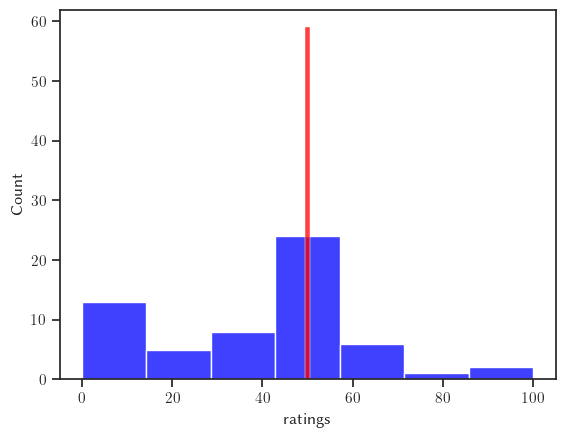

In [4]:
plt.hist(ratings, density=True, bins=30)  # density=False would make counts
midpoint = np.ones(len(ratings)) * 50

df = pd.DataFrame({
    'ratings': ratings,
    'midpoint': midpoint,
})
sns.histplot(data=df, x='ratings', color='blue')
sns.histplot(data=df, x='midpoint', color='red')
df.to_csv('processed/scales.csv', index=False)